# Лабораторная работа №3

In [ ]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch
from scipy.stats import loguniform, randint
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.model_selection import (
    GridSearchCV,
    KFold,
    RandomizedSearchCV,
    cross_validate,
    train_test_split,
    validation_curve,
)


RANDOM_STATE = 42          
SPLIT_RANDOM_STATE = 48     
TEST_SIZE = 0.20

#для гиперпараметров
CV_FOLDS = 5
N_ITER = 30                 
SCORING = "neg_root_mean_squared_error"
N_JOBS = -1

BASELINE_PARAMS = {"n_estimators": 100}

DEPTH_RANGE = [1, 2, 3, 4, 5, 6, 8, 10, 12, 15]
LR_RANGE = [0.003, 0.01, 0.03, 0.1, 0.3, 0.6, 1.0]
MAX_STAGES = 2000#до скольких деревьев строим кривую по n_estimators
REGION_TOL = 0.005#CV RMSE не хуже минимума больше чем на эту величину
SAME_MEAN_TOL = 0.002#«одинаковое среднее» в анализе устойчивости

#для графиков
COLORS = {"train": "#eb6834", "cv": "#2a78d6", "Baseline": "#898781",
          "Grid Search": "#2a78d6", "Random Search": "#1baf7a", "highlight": "#e34948"}
REGION_COLORS = {"under": "#eeeae0", "good": "#dcefe2", "over": "#f9dfd6"}
REGION_NAMES = {"under": "недообучение", "good": "разумная сложность", "over": "переобучение"}

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e1e0d9",
    "grid.linewidth": 0.8,
    "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "lines.linewidth": 2,
})

Данные и разбиение train/test точно как в ЛР №1, тестовая выборка совпадает ЛР №1, там был RMSE = 0.678

In [2]:
df_white = pd.read_csv("winequality-white.csv", sep=";")
df_red = pd.read_csv("winequality-red.csv", sep=";")
df_white["wine_type"] = 0
df_red["wine_type"] = 1
df = pd.concat([df_white, df_red], ignore_index=True)

X = df.drop(columns=["quality"])
y = df["quality"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=SPLIT_RANDOM_STATE
)

cv = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)

print("Весь датасет:", df.shape)
print("Train:", X_train.shape, "  Test:", X_test.shape)
print(f"Один fold: обучение ≈ {len(X_train) * (CV_FOLDS - 1) // CV_FOLDS} объектов, "
      f"валидация ≈ {len(X_train) // CV_FOLDS} объектов")

Весь датасет: (6497, 13)
Train: (5197, 12)   Test: (1300, 12)
Один fold: обучение ≈ 4157 объектов, валидация ≈ 1039 объектов


### Выбор числа folds

Используем **5-fold `KFold` с перемешиванием**:

* В train 5197 объектов. При 5 folds модель на каждом шаге учится на ~4160 объектах (80% train) — это близко к размеру выборки, на которой будет обучаться финальная модель, поэтому оценка не слишком пессимистична. Валидационная часть (~1040 объектов) достаточно большая, чтобы RMSE на ней был не слишком шумным.
* 10 folds увеличили бы время поиска в 2 раза (480 обучений вместо 240 для сетки), а обучающая часть выросла бы всего с 80% до 90%. 3 folds — обучение лишь на 67% данных и всего 3 точки для оценки разброса.
* `shuffle=True` нужен, потому что исходный датафрейм упорядочен (сначала белые вина, потом красные). Фиксированный `random_state` гарантирует, что **все модели (baseline, Grid Search, Random Search, кривые валидации) оцениваются на одних и тех же folds** — их можно сравнивать попарно по каждому fold (раздел 8).

### Вопросы

**Зачем нужна кросс-валидация?** Чтобы оценить качество модели на данных, которые она не видела, используя только обучающую выборку. Каждый объект train ровно один раз попадает в валидацию, а итоговая оценка — среднее по 5 разбиениям, поэтому она гораздо стабильнее оценки по одному разбиению. Дополнительно мы видим разброс качества между folds.

**Почему одного разбиения train/test недостаточно для подбора параметров?** Оценка по одной отложенной части — случайная величина: она зависит от того, какие объекты в неё попали. Ниже видно, что у baseline RMSE по разным folds отличается на несколько сотых — это того же порядка, что и разница между многими комбинациями гиперпараметров. По одному разбиению мы выбирали бы не лучшую модель, а ту, которой «повезло» со сплитом. Кроме того, если подбирать параметры на test, для финальной честной проверки не остаётся независимых данных.

**Что будет, если многократно выбирать гиперпараметры по test?** Test фактически становится частью обучения: мы подгоняем модель под конкретные 1300 объектов, включая их шум. Чем больше конфигураций сравнили на test, тем сильнее выбранная оценка смещена в лучшую сторону (выбираем максимум из шумных оценок). В итоге качество на test будет завышенным и перестанет отражать качество на новых данных — честной оценки обобщающей способности больше нет.

In [3]:
baseline = GradientBoostingRegressor(**BASELINE_PARAMS, random_state=RANDOM_STATE)
baseline_cv = cross_validate(baseline, X_train, y_train, cv=cv, scoring=SCORING, n_jobs=N_JOBS)
baseline_folds = -baseline_cv["test_score"]

shown = ["n_estimators", "learning_rate", "max_depth", "subsample", "min_samples_leaf", "loss"]
print("Параметры baseline:", {name: baseline.get_params()[name] for name in shown})
print("RMSE по folds:", np.round(baseline_folds, 4))
print(f"Baseline CV RMSE: {baseline_folds.mean():.4f} ± {baseline_folds.std():.4f}")

Параметры baseline: {'n_estimators': 100, 'learning_rate': 0.1, 'max_depth': 3, 'subsample': 1.0, 'min_samples_leaf': 1, 'loss': 'squared_error'}
RMSE по folds: [0.6649 0.6976 0.7027 0.6969 0.68  ]
Baseline CV RMSE: 0.6884 ± 0.0140


## 4. Гиперпараметры

Выбираем три ключевых гиперпараметра бустинга. Остальные (`subsample`, `min_samples_leaf`, `max_features`) не трогаем: задача — понять влияние параметров, а не раздуть пространство поиска. Уже сетка 4 × 3 × 4 = 48 комбинаций при 5 folds — это 240 обучений.

| Гиперпараметр | Смысл | Диапазон | Ожидаемое влияние |
|---|---|---|---|
| `n_estimators` | Число деревьев, т.е. шагов бустинга. Каждое следующее дерево обучается на остатках (ошибках) текущего ансамбля. | 50 – 400 | Мало деревьев — модель не успевает приблизиться к зависимости (недообучение). С ростом числа деревьев ошибка на train падает почти до нуля, а на CV сначала падает, потом выходит на плато и может начать расти (переобучение). |
| `learning_rate` | Shrinkage — коэффициент, с которым вклад каждого дерева добавляется к ансамблю. | 0.01 – 0.1, по логарифмической шкале | Маленький шаг: модель учится медленно, нужно больше деревьев, но обобщает обычно лучше. Большой шаг: быстро подгоняется под train и легко переобучается. Работает в паре с `n_estimators`: важно скорее их «произведение». |
| `max_depth` | Глубина каждого дерева = максимальный порядок взаимодействий признаков, который может уловить одно дерево. | 1 – 4 | `max_depth=1` (пни) — аддитивная модель без взаимодействий, скорее недообучение. Чем глубже деревья, тем сложнее модель: она ловит взаимодействия (например, `alcohol` × `volatile acidity` × тип вина), но при слишком большой глубине начинает запоминать объекты. |

`learning_rate` перебираем по логарифмической шкале (0.01, 0.03, 0.1), потому что его влияние мультипликативное: разница между 0.01 и 0.03 так же важна, как между 0.03 и 0.1.

## Grid Search

Полный перебор по заранее заданной сетке. Те же folds cv, что и для baseline

In [ ]:
def fmt_params(params):
    # Нампай числа в обычные а learning_rate округляется
    return {k: round(float(v), 4) if isinstance(v, float) else int(v) for k, v in params.items()}


def fold_scores(search):
    # RMSE лучшей комбинации на каждом fold (знак меняем обратно)
    return -np.array([search.cv_results_[f"split{i}_test_score"][search.best_index_]
                      for i in range(CV_FOLDS)])


def results_table(search):
    # Все проверенные комбинации, отсортированные по CV RMSE
    res = search.cv_results_
    table = pd.DataFrame(list(res["params"]))
    table["CV RMSE"] = -res["mean_test_score"]
    table["CV std"] = res["std_test_score"]
    table["fit, с"] = res["mean_fit_time"]
    for i in range(CV_FOLDS):
        table[f"fold {i + 1}"] = -res[f"split{i}_test_score"]
    return table.sort_values("CV RMSE").reset_index(drop=True)

In [5]:
param_grid = {
    "n_estimators": [50, 100, 200, 400],
    "learning_rate": [0.01, 0.03, 0.1],
    "max_depth": [1, 2, 3, 4],
}

grid = GridSearchCV(
    GradientBoostingRegressor(random_state=RANDOM_STATE),
    param_grid=param_grid,
    scoring=SCORING,
    cv=cv,
    n_jobs=N_JOBS,
)

start = time.perf_counter()
grid.fit(X_train, y_train)
grid_time = time.perf_counter() - start

In [18]:
grid_table = results_table(grid)
grid_folds = fold_scores(grid)
n_combinations = len(grid_table)

print("Пространство поиска:", param_grid)
print(f"Проверено комбинаций: {n_combinations} (обучений моделей: {n_combinations * CV_FOLDS})")
print("Лучшие параметры:", grid.best_params_)
print(f"CV RMSE лучшей модели: {-grid.best_score_:.4f} плюс минус {grid_folds.std():.4f}")
print(f"Время поиска: {grid_time:.1f} с")

display(grid_table.head(10)[["n_estimators", "learning_rate", "max_depth", "CV RMSE", "CV std", "fit, с"]].round(4))

Пространство поиска: {'n_estimators': [50, 100, 200, 400], 'learning_rate': [0.01, 0.03, 0.1], 'max_depth': [1, 2, 3, 4]}
Проверено комбинаций: 48 (обучений моделей: 240)
Лучшие параметры: {'learning_rate': 0.1, 'max_depth': 4, 'n_estimators': 400}
CV RMSE лучшей модели: 0.6567 плюс минус 0.0124
Время поиска: 24.5 с


,n_estimators,learning_rate,max_depth,CV RMSE,CV std,"fit, с"
0,400,0.10,4,0.6567,0.0124,2.9081
1,200,0.10,4,0.6679,0.0126,1.8329
2,400,0.10,3,0.6722,0.0127,2.6992
3,400,0.03,4,0.6743,0.0135,3.6850
4,100,0.10,4,0.6784,0.0143,0.9148
5,200,0.10,3,0.6800,0.0122,1.4271
6,200,0.03,4,0.6854,0.0155,1.7195
7,400,0.10,2,0.6873,0.0103,1.8034
8,400,0.03,3,0.6873,0.0129,2.7598
9,100,0.10,3,0.6884,0.0140,0.6941


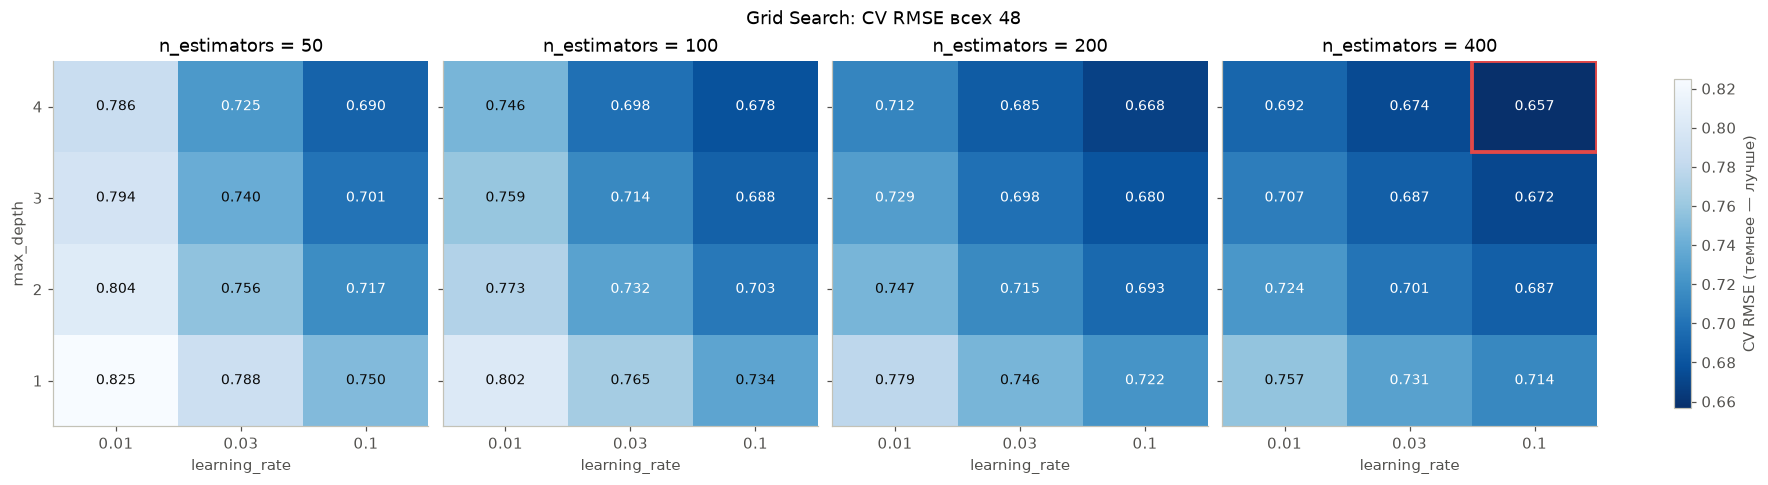

In [19]:
n_values = param_grid["n_estimators"]
lr_values = param_grid["learning_rate"]
depth_values = param_grid["max_depth"]
vmin, vmax = grid_table["CV RMSE"].min(), grid_table["CV RMSE"].max()

fig, axes = plt.subplots(1, len(n_values), figsize=(16, 4.3), sharey=True, layout="constrained")
for ax, n in zip(axes, n_values):
    sub = (grid_table[grid_table["n_estimators"] == n]
           .pivot(index="max_depth", columns="learning_rate", values="CV RMSE"))
    image = ax.imshow(sub.values, cmap="Blues_r", vmin=vmin, vmax=vmax, origin="lower", aspect="auto")
    for i, depth in enumerate(sub.index):
        for j, lr in enumerate(sub.columns):
            value = sub.loc[depth, lr]
            dark_cell = (value - vmin) / (vmax - vmin) < 0.45
            ax.text(j, i, f"{value:.3f}", ha="center", va="center", fontsize=9,
                    color="white" if dark_cell else "#0b0b0b")
    ax.set_xticks(range(len(sub.columns)), sub.columns)
    ax.set_yticks(range(len(sub.index)), sub.index)
    ax.set_xlabel("learning_rate")
    ax.set_title(f"n_estimators = {n}")
    ax.grid(False)
axes[0].set_ylabel("max_depth")

best = grid.best_params_
best_ax = axes[n_values.index(best["n_estimators"])]
best_ax.add_patch(plt.Rectangle(
    (lr_values.index(best["learning_rate"]) - 0.5, depth_values.index(best["max_depth"]) - 0.5), 1, 1,
    fill=False, edgecolor=COLORS["highlight"], linewidth=2.5))
fig.colorbar(image, ax=axes, label="CV RMSE (темнее — лучше)", shrink=0.9)
fig.suptitle(f"Grid Search: CV RMSE всех {n_combinations} ")
plt.show()

**Наблюдения по Grid Search.**

* Лучшая комбинация — `n_estimators=400, learning_rate=0.1, max_depth=4`: CV RMSE ≈ 0.657 против 0.688 у baseline.
* Хорошо видна связка `learning_rate` × `n_estimators`: при `learning_rate=0.01` и 50 деревьях модель почти ничему не научилась (RMSE 0.79–0.83, заметно хуже baseline), а при 400 деревьях тот же шаг уже даёт разумный результат. Маленький шаг требует больше деревьев.
* Пни (`max_depth=1`) проигрывают при любых других параметрах — взаимодействия признаков важны.
* **Лучшая точка лежит в углу сетки**: все три параметра на максимальных значениях. Это сигнал, что настоящий оптимум, скорее всего, за пределами сетки. В разделе 6 проверим это кривыми валидации (тоже только на train).

## 6. Random Search

Ищем в **тех же границах**, что и сетка, но значения берём из непрерывных распределений:

* `n_estimators` — любое целое от 50 до 400;
* `learning_rate` — лог-равномерно от 0.01 до 0.1 (интервалы 0.01–0.03 и 0.03–0.1 выбираются одинаково часто, как и в сетке);
* `max_depth` — целое от 1 до 4.

Бюджет — `N_ITER = 30` комбинаций против 48 у сетки, т.е. сопоставимый (≈60%). Folds те же.

In [8]:
param_distributions = {
    "n_estimators": randint(50, 401),
    "learning_rate": loguniform(0.01, 0.1),
    "max_depth": randint(1, 5),
}

random_search = RandomizedSearchCV(
    GradientBoostingRegressor(random_state=RANDOM_STATE),
    param_distributions=param_distributions,
    n_iter=N_ITER,
    scoring=SCORING,
    cv=cv,
    n_jobs=N_JOBS,
    random_state=RANDOM_STATE,
)

start = time.perf_counter()
random_search.fit(X_train, y_train)
random_time = time.perf_counter() - start

In [9]:
random_table = results_table(random_search)
random_folds = fold_scores(random_search)

print("Лучшие параметры:", fmt_params(random_search.best_params_))
print(f"CV RMSE лучшей модели: {-random_search.best_score_:.4f} ± {random_folds.std():.4f}")
print(f"Время поиска: {random_time:.1f} с")

comparison = pd.DataFrame({
    "Комбинаций": [n_combinations, N_ITER],
    "Обучений моделей": [n_combinations * CV_FOLDS, N_ITER * CV_FOLDS],
    "Время, с": [grid_time, random_time],
    "Лучший CV RMSE": [-grid.best_score_, -random_search.best_score_],
    "Разных n_estimators": [grid_table["n_estimators"].nunique(), random_table["n_estimators"].nunique()],
    "Разных learning_rate": [grid_table["learning_rate"].nunique(), random_table["learning_rate"].nunique()],
    "Лучшие параметры": [fmt_params(grid.best_params_), fmt_params(random_search.best_params_)],
}, index=["Grid Search", "Random Search"])
display(comparison.round(4))
display(random_table.head(10)[["n_estimators", "learning_rate", "max_depth", "CV RMSE", "CV std", "fit, с"]].round(4))

Лучшие параметры: {'learning_rate': 0.0695, 'max_depth': 4, 'n_estimators': 211}
CV RMSE лучшей модели: 0.6707 ± 0.0137
Время поиска: 17.4 с


,Комбинаций,Обучений моделей,"Время, с",Лучший CV RMSE,Разных n_estimators,Разных learning_rate,Лучшие параметры
Grid Search,48,240,24.5231,0.6567,4,3,"{'learning_rate': 0.1, 'max_depth': 4, 'n_esti..."
Random Search,30,150,17.4338,0.6707,28,30,"{'learning_rate': 0.0695, 'max_depth': 4, 'n_e..."


,n_estimators,learning_rate,max_depth,CV RMSE,CV std,"fit, с"
0,211,0.0695,4,0.6707,0.0137,1.8438
1,266,0.0346,4,0.6775,0.0142,1.8979
2,369,0.0241,4,0.6784,0.0135,3.2271
3,319,0.0248,4,0.6803,0.0139,2.6687
4,264,0.0534,3,0.6854,0.0123,1.7648
5,313,0.0174,4,0.6866,0.0156,2.8754
6,343,0.0114,4,0.6917,0.0161,2.9910
7,320,0.0111,4,0.6935,0.0168,2.6342
8,219,0.0335,3,0.6945,0.0145,1.3687
9,326,0.0100,4,0.6956,0.0171,2.6941


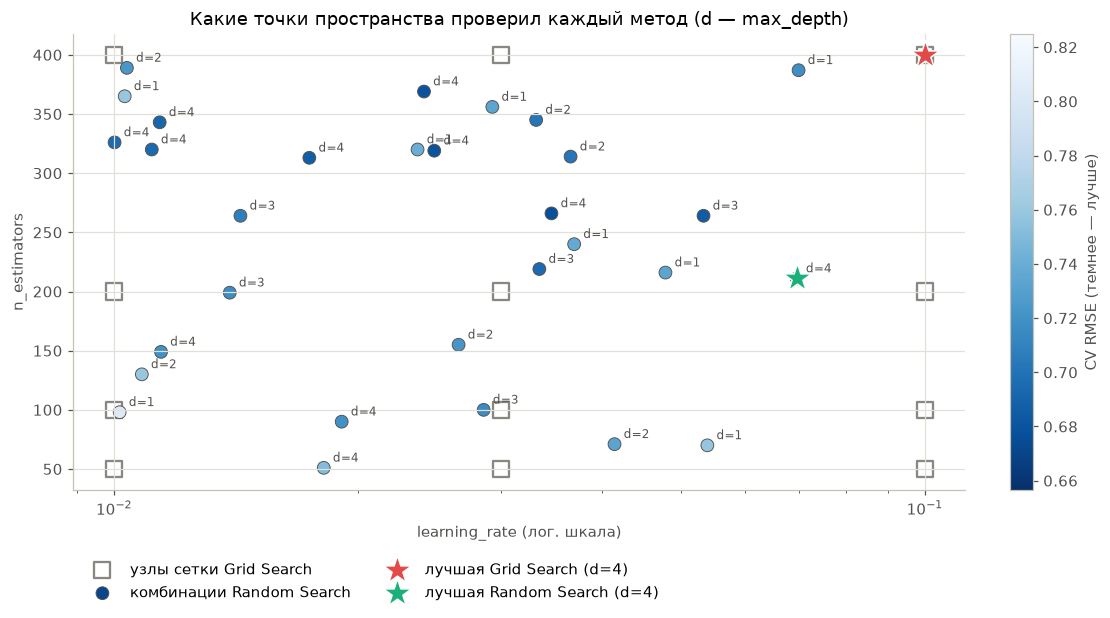

In [20]:
fig, ax = plt.subplots(figsize=(10, 5.5), layout="constrained")

grid_lr, grid_n = np.meshgrid(lr_values, n_values)
ax.scatter(grid_lr.ravel(), grid_n.ravel(), marker="s", s=110, facecolors="none",
           edgecolors="#898781", linewidths=1.5, label="узлы сетки Grid Search")
points = ax.scatter(random_table["learning_rate"], random_table["n_estimators"], c=random_table["CV RMSE"],
                    cmap="Blues_r", vmin=vmin, vmax=vmax, s=70, edgecolors="#52514e", linewidths=0.6,
                    label="комбинации Random Search")
for _, row in random_table.iterrows():
    ax.annotate(f"d={int(row['max_depth'])}", (row["learning_rate"], row["n_estimators"]),
                xytext=(6, 4), textcoords="offset points", fontsize=8, color="#52514e")

ax.scatter(best["learning_rate"], best["n_estimators"], marker="*", s=380, color=COLORS["highlight"],
           edgecolors="white", zorder=5, label=f"лучшая Grid Search (d={best['max_depth']})")
rbest = random_search.best_params_
ax.scatter(rbest["learning_rate"], rbest["n_estimators"], marker="*", s=380, color=COLORS["Random Search"],
           edgecolors="white", zorder=5, label=f"лучшая Random Search (d={rbest['max_depth']})")

ax.set_xscale("log")
ax.set_xlabel("learning_rate (лог. шкала)")
ax.set_ylabel("n_estimators")
ax.set_title("Какие точки пространства проверил каждый метод (d — max_depth)")
fig.colorbar(points, ax=ax, label="CV RMSE (темнее — лучше)")
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.13), ncol=2, frameon=False)
plt.show()

**Сравнение Random Search и Grid Search** (числа — в таблице выше).

* **Качество.** Здесь Random Search нашёл комбинацию хуже (CV RMSE ≈ 0.671 против 0.657). Причина — оптимум лежит в углу пространства (все три параметра на максимуме). Сетка включает этот угол по построению, а случайная точка попадает рядом с ним редко: вероятность одновременно получить `max_depth=4`, `learning_rate > 0.07` и `n_estimators > 350` — около 1/4 · 0.15 · 0.14 ≈ 0.5% на одну попытку. Лучшая найденная точка (`max_depth=4`, `learning_rate≈0.07`, `n_estimators≈210`) находится в той же области, но не дошла до угла.
* **Число комбинаций.** 30 против 48, при этом Random Search проверил 30 разных значений `learning_rate` и `n_estimators`, а сетка — только 3 и 4.
* **Время.** Random Search быстрее, потому что комбинаций меньше, но не ровно в 48/30 раза: время обучения растёт с `n_estimators` и `max_depth`, а случайный поиск в среднем брал больше деревьев (равномерно от 50 до 400, в среднем ≈ 225 против 187.5 в сетке).

**Когда случайный поиск предпочтительнее полного перебора:**

1. Параметров много, а реально важны лишь некоторые. Сетка тратит бюджет на повторы по неважным осям: при 3 значениях на ось она проверит всего 3 разных значения важного параметра, а случайный поиск с тем же бюджетом — столько, сколько итераций.
2. Параметры непрерывные (`learning_rate`, регуляризация) и заранее неясно, где их оптимум, — сетка проверяет только заранее выбранные точки.
3. Пространство большое: размер сетки растёт экспоненциально с числом параметров, а бюджет случайного поиска задаётся явно (`n_iter`) и не зависит от размерности. Поиск можно остановить в любой момент и получить лучший результат на текущий момент.

Grid Search уместен, как здесь, когда параметров мало, пространство маленькое и дискретное и его можно перебрать целиком.

## 7. Влияние гиперпараметров

Для каждого из трёх параметров строим зависимость RMSE на **train** и на **CV** (те же 5 folds, только обучающая выборка), фиксируя остальные параметры на лучших значениях Grid Search. Диапазоны специально шире, чем в сетке, чтобы увидеть все режимы.

Зоны на графиках определяются автоматически по CV RMSE:
* **разумная сложность** — CV RMSE не хуже минимума больше чем на `REGION_TOL = 0.005`;
* **недообучение** — левее минимума и заметно хуже (модель слишком простая: высокая ошибка и на train, и на CV);
* **переобучение** — правее минимума и заметно хуже (ошибка на train продолжает падать, на CV растёт).

Для `n_estimators` не нужно обучать модель 2000 раз: `staged_predict` даёт предсказания ансамбля после каждого дерева, поэтому достаточно одной модели на каждый fold.

In [11]:
def run_validation_curve(param_name, param_range, **fixed_params):
    train_scores, cv_scores = validation_curve(
        GradientBoostingRegressor(random_state=RANDOM_STATE, **fixed_params),
        X_train, y_train,
        param_name=param_name, param_range=param_range,
        cv=cv, scoring=SCORING, n_jobs=N_JOBS,
    )
    return -train_scores, -cv_scores          # shape: (число значений, CV_FOLDS)


def fixed_except(name):
    return {k: v for k, v in grid.best_params_.items() if k != name}


start = time.perf_counter()
depth_train, depth_cv = run_validation_curve("max_depth", DEPTH_RANGE, **fixed_except("max_depth"))
lr_train, lr_cv = run_validation_curve("learning_rate", LR_RANGE, **fixed_except("learning_rate"))

stages = np.arange(1, MAX_STAGES + 1)
stages_train = np.zeros((MAX_STAGES, CV_FOLDS))
stages_cv = np.zeros((MAX_STAGES, CV_FOLDS))
staged_params = {**grid.best_params_, "n_estimators": MAX_STAGES}
for k, (train_idx, val_idx) in enumerate(cv.split(X_train)):
    X_tr, y_tr = X_train.iloc[train_idx], y_train.iloc[train_idx]
    X_val, y_val = X_train.iloc[val_idx], y_train.iloc[val_idx]
    model = GradientBoostingRegressor(**staged_params, random_state=RANDOM_STATE).fit(X_tr, y_tr)
    stages_train[:, k] = [root_mean_squared_error(y_tr, p) for p in model.staged_predict(X_tr)]
    stages_cv[:, k] = [root_mean_squared_error(y_val, p) for p in model.staged_predict(X_val)]
print(f"Кривые построены за {time.perf_counter() - start:.1f} с")

Кривые построены за 100.5 с


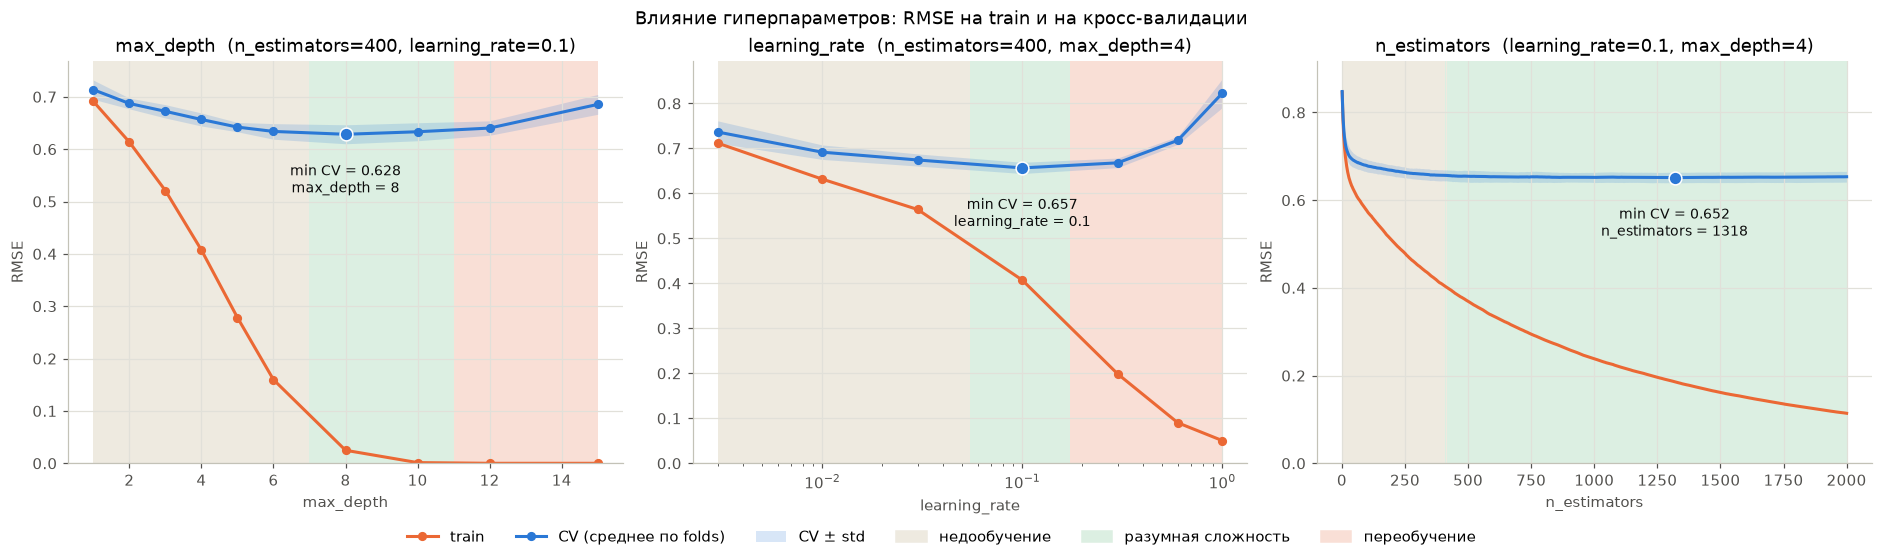

,max_depth,train RMSE,CV RMSE,CV std,зона
0,1,0.6913,0.7135,0.0183,недообучение
1,2,0.6136,0.6873,0.0103,недообучение
2,3,0.5210,0.6722,0.0127,недообучение
3,4,0.4074,0.6567,0.0124,недообучение
4,5,0.2784,0.6421,0.0090,недообучение
5,6,0.1597,0.6339,0.0149,недообучение
6,8,0.0249,0.6284,0.0181,разумная сложность
7,10,0.0013,0.6332,0.0172,разумная сложность
8,12,0.0000,0.6403,0.0138,переобучение
9,15,0.0000,0.6855,0.0189,переобучение


,learning_rate,train RMSE,CV RMSE,CV std,зона
0,0.003,0.7117,0.7365,0.0248,недообучение
1,0.010,0.6317,0.6916,0.0161,недообучение
2,0.030,0.5643,0.6743,0.0135,недообучение
3,0.100,0.4074,0.6567,0.0124,разумная сложность
4,0.300,0.1988,0.6679,0.0106,переобучение
5,0.600,0.0901,0.7179,0.0090,переобучение
6,1.000,0.0506,0.8224,0.0318,переобучение


,n_estimators,train RMSE,CV RMSE,CV std,зона
9,10,0.7223,0.7436,0.0249,недообучение
49,50,0.6195,0.6896,0.0158,недообучение
99,100,0.5749,0.6784,0.0143,недообучение
199,200,0.5069,0.6679,0.0126,недообучение
399,400,0.4074,0.6567,0.0124,недообучение
599,600,0.3360,0.6535,0.0125,разумная сложность
799,800,0.2820,0.6529,0.0122,разумная сложность
999,1000,0.2382,0.6519,0.0116,разумная сложность
1499,1500,0.1617,0.6523,0.0121,разумная сложность
1999,2000,0.1140,0.6535,0.0122,разумная сложность


In [12]:
def label_regions(cv_mean, tol=REGION_TOL):
    best_idx = int(np.argmin(cv_mean))
    return ["good" if score <= cv_mean[best_idx] + tol else ("under" if i < best_idx else "over")
            for i, score in enumerate(cv_mean)]


def shade_regions(ax, values, labels, log=False):
    values = np.asarray(values, dtype=float)
    mids = np.sqrt(values[:-1] * values[1:]) if log else (values[:-1] + values[1:]) / 2
    edges = np.concatenate([[values[0]], mids, [values[-1]]])
    start = 0
    for i in range(1, len(labels) + 1):
        if i == len(labels) or labels[i] != labels[start]:
            ax.axvspan(edges[start], edges[i], color=REGION_COLORS[labels[start]], lw=0, zorder=0)
            start = i


def plot_curve(ax, values, train_rmse, cv_rmse, name, log=False, markers=True):
    values = np.asarray(values)
    train_mean, cv_mean, cv_std = train_rmse.mean(axis=1), cv_rmse.mean(axis=1), cv_rmse.std(axis=1)
    labels = label_regions(cv_mean)
    shade_regions(ax, values, labels, log)
    marker = "o" if markers else None
    ax.plot(values, train_mean, color=COLORS["train"], marker=marker, markersize=5, label="train")
    ax.plot(values, cv_mean, color=COLORS["cv"], marker=marker, markersize=5, label="CV (среднее по folds)")
    ax.fill_between(values, cv_mean - cv_std, cv_mean + cv_std, color=COLORS["cv"], alpha=0.18, lw=0,
                    label="CV ± std")
    best_idx = int(np.argmin(cv_mean))
    ax.scatter(values[best_idx], cv_mean[best_idx], s=70, color=COLORS["cv"], edgecolors="white", zorder=5)
    ax.annotate(f"min CV = {cv_mean[best_idx]:.3f}\n{name} = {values[best_idx]:g}",
                (values[best_idx], cv_mean[best_idx]), xytext=(0, -38), textcoords="offset points",
                ha="center", fontsize=9, color="#0b0b0b")
    if log:
        ax.set_xscale("log")
    ax.set_xlabel(name)
    ax.set_ylabel("RMSE")
    return pd.DataFrame({name: values, "train RMSE": train_mean, "CV RMSE": cv_mean, "CV std": cv_std,
                         "зона": [REGION_NAMES[label] for label in labels]})


fig, axes = plt.subplots(1, 3, figsize=(17, 5), layout="constrained")
depth_table = plot_curve(axes[0], DEPTH_RANGE, depth_train, depth_cv, "max_depth")
axes[0].set_title(f"max_depth  (n_estimators={best['n_estimators']}, learning_rate={best['learning_rate']})")
lr_table = plot_curve(axes[1], LR_RANGE, lr_train, lr_cv, "learning_rate", log=True)
axes[1].set_title(f"learning_rate  (n_estimators={best['n_estimators']}, max_depth={best['max_depth']})")
stages_table = plot_curve(axes[2], stages, stages_train, stages_cv, "n_estimators", markers=False)
axes[2].set_title(f"n_estimators  (learning_rate={best['learning_rate']}, max_depth={best['max_depth']})")
for ax in axes:
    ax.set_ylim(0, None)

handles, _ = axes[0].get_legend_handles_labels()
handles += [Patch(color=REGION_COLORS[key], label=REGION_NAMES[key]) for key in REGION_COLORS]
fig.legend(handles=handles, loc="outside lower center", ncol=6, frameon=False)
fig.suptitle("Влияние гиперпараметров: RMSE на train и на кросс-валидации")
plt.show()

checkpoints = [10, 50, 100, 200, 400, 600, 800, 1000, 1500, 2000]
display(depth_table.round(4))
display(lr_table.round(4))
display(stages_table[stages_table["n_estimators"].isin(checkpoints)].round(4))



Финальная модель  GradientBoostingRegressor с grid.best_params_, обученный на всём train.

Только теперь впервые используем `X_test`. Для сравнения test-метрики считаем и для двух других моделей, но на выбор это уже не влияет — он сделан выше.

In [13]:
final_model = GradientBoostingRegressor(**grid.best_params_, random_state=RANDOM_STATE)
final_model.fit(X_train, y_train)

candidates = {
    "Baseline": (BASELINE_PARAMS, baseline_folds),
    "Grid Search": (grid.best_params_, grid_folds),
    "Random Search": (random_search.best_params_, random_folds),
}

rows = []
for name, (params, folds) in candidates.items():
    if name == "Grid Search":
        model = final_model
    else:
        model = GradientBoostingRegressor(**params, random_state=RANDOM_STATE).fit(X_train, y_train)
    pred = model.predict(X_test)
    rows.append({
        "Модель": name,
        "Параметры": fmt_params(params),
        "CV RMSE": folds.mean(),
        "CV std": folds.std(),
        "Test RMSE": root_mean_squared_error(y_test, pred),
        "Test MAE": mean_absolute_error(y_test, pred),
    })

results = pd.DataFrame(rows).set_index("Модель")
base_cv, base_test = results.loc["Baseline", ["CV RMSE", "Test RMSE"]]
results["Улучшение CV, %"] = (base_cv - results["CV RMSE"]) / base_cv * 100
results["Улучшение Test, %"] = (base_test - results["Test RMSE"]) / base_test * 100
results["Test − CV"] = results["Test RMSE"] - results["CV RMSE"]
display(results.round(4))

,Параметры,CV RMSE,CV std,Test RMSE,Test MAE,"Улучшение CV, %","Улучшение Test, %",Test − CV
Модель,,,,,,,,
Baseline,{'n_estimators': 100},0.6884,0.0140,0.6783,0.5359,0.0000,0.0000,-0.0101
Grid Search,"{'learning_rate': 0.1, 'max_depth': 4, 'n_esti...",0.6567,0.0124,0.6401,0.4880,4.6139,5.6338,-0.0166
Random Search,"{'learning_rate': 0.0695, 'max_depth': 4, 'n_e...",0.6707,0.0137,0.6576,0.5108,2.5786,3.0559,-0.0131


А теперь проверка на устойчивость(прямо как в презентации🤓)

In [ ]:
folds_df = pd.DataFrame({"Baseline": baseline_folds, "Grid Search": grid_folds, "Random Search": random_folds},
                        index=[f"fold {i + 1}" for i in range(CV_FOLDS)])
stability = pd.DataFrame({
    "mean": folds_df.mean(),
    "std": folds_df.std(ddof=0),
    "min": folds_df.min(),
    "max": folds_df.max(),
})
stability["размах (max − min)"] = stability["max"] - stability["min"]
display(folds_df.round(4))
display(stability.round(4))

gain = folds_df["Baseline"] - folds_df["Grid Search"]
print(f"Grid Search лучше baseline на {(gain > 0).sum()} из {CV_FOLDS} folds; "
      f"выигрыш по folds: от {gain.min():.4f} до {gain.max():.4f}")

# Пара комбинаций из сетки с почти одинаковым средним, но максимально разным разбросом
same_mean_pair, max_std_diff = None, 0.0
for i in range(n_combinations):
    for j in range(i + 1, n_combinations):
        a, b = grid_table.iloc[i], grid_table.iloc[j]
        std_diff = abs(a["CV std"] - b["CV std"])
        if abs(a["CV RMSE"] - b["CV RMSE"]) <= SAME_MEAN_TOL and std_diff > max_std_diff:
            same_mean_pair, max_std_diff = (i, j), std_diff
pair_table = grid_table.iloc[list(same_mean_pair)]
print(f"\nКомбинации с почти одинаковым средним (разница ≤ {SAME_MEAN_TOL}), но разным разбросом:")
display(pair_table.round(4))

,Baseline,Grid Search,Random Search
fold 1,0.6649,0.6407,0.6490
fold 2,0.6976,0.6483,0.6703
fold 3,0.7027,0.6769,0.6877
fold 4,0.6969,0.6629,0.6826
fold 5,0.6800,0.6546,0.6639


,mean,std,min,max,размах (max − min)
Baseline,0.6884,0.0140,0.6649,0.7027,0.0377
Grid Search,0.6567,0.0124,0.6407,0.6769,0.0361
Random Search,0.6707,0.0137,0.6490,0.6877,0.0387


Grid Search лучше baseline на 5 из 5 folds; выигрыш по folds: от 0.0242 до 0.0493

Комбинации с почти одинаковым средним (разница ≤ 0.002), но разным разбросом:


,learning_rate,max_depth,n_estimators,CV RMSE,CV std,"fit, с",fold 1,fold 2,fold 3,fold 4,fold 5
6,0.03,4,200,0.6854,0.0155,1.7195,0.6597,0.6975,0.6979,0.6968,0.6749
7,0.10,2,400,0.6873,0.0103,1.8034,0.6722,0.6919,0.7027,0.6884,0.6810


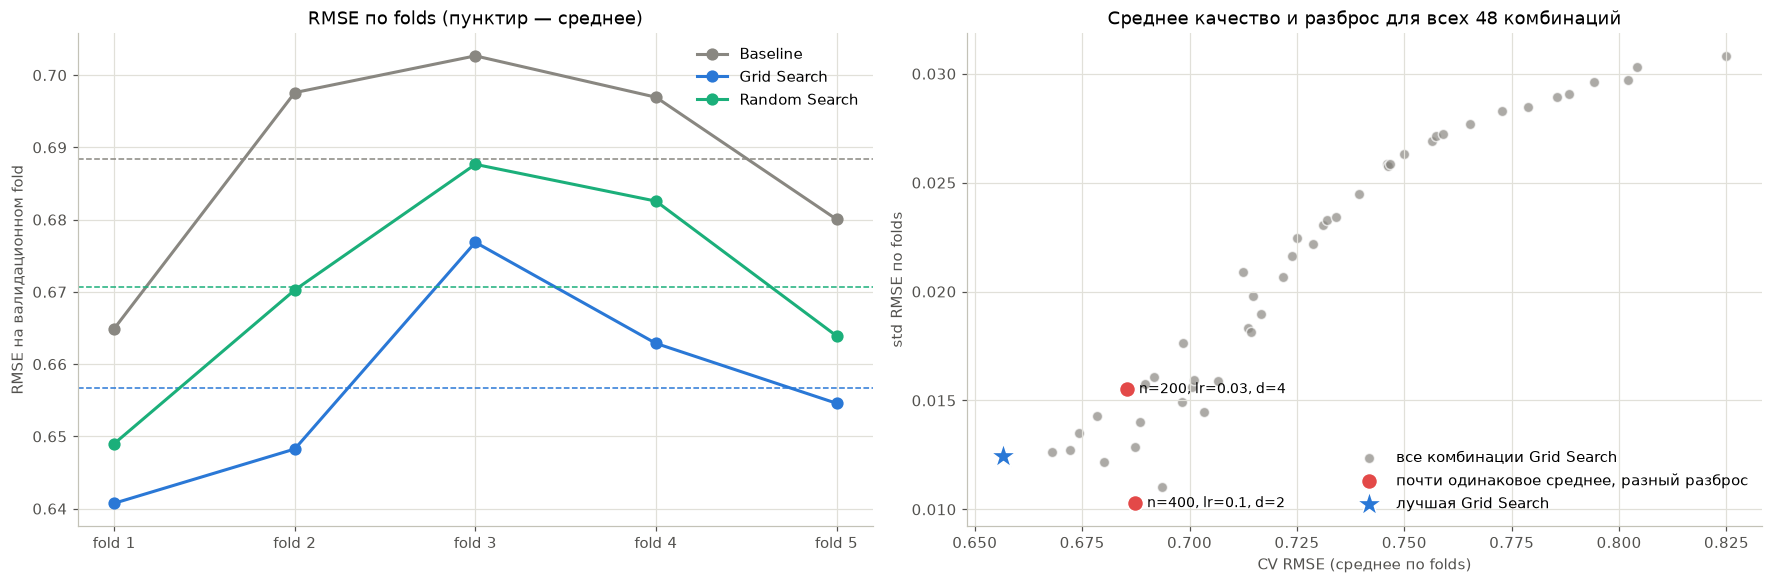

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.2), layout="constrained")

fold_numbers = np.arange(1, CV_FOLDS + 1)
for name in folds_df.columns:
    axes[0].plot(fold_numbers, folds_df[name], marker="o", markersize=7, color=COLORS[name], label=name)
    axes[0].axhline(folds_df[name].mean(), color=COLORS[name], linestyle="--", linewidth=1)
axes[0].set_xticks(fold_numbers, folds_df.index)
axes[0].set_ylabel("RMSE на валидационном fold")
axes[0].set_title("RMSE по folds (пунктир — среднее)")
axes[0].legend(frameon=False)

ax = axes[1]
ax.scatter(grid_table["CV RMSE"], grid_table["CV std"], s=45, color="#898781", alpha=0.7,
           edgecolors="white", label="все комбинации Grid Search")
ax.scatter(pair_table["CV RMSE"], pair_table["CV std"], s=110, color=COLORS["highlight"],
           edgecolors="white", zorder=5, label="почти одинаковое среднее, разный разброс")
for _, row in pair_table.iterrows():
    ax.annotate(f"n={int(row['n_estimators'])}, lr={row['learning_rate']}, d={int(row['max_depth'])}",
                (row["CV RMSE"], row["CV std"]), xytext=(8, 0), textcoords="offset points",
                va="center", fontsize=9)
ax.scatter(-grid.best_score_, grid_folds.std(), marker="*", s=300, color=COLORS["Grid Search"],
           edgecolors="white", zorder=6, label="лучшая Grid Search")
ax.set_xlabel("CV RMSE (среднее по folds)")
ax.set_ylabel("std RMSE по folds")
ax.set_title("Среднее качество и разброс для всех 48 комбинаций")
ax.legend(frameon=False, loc="lower right")
plt.show()

**Разброс значений.**
* У всех трёх моделей разброс по folds похож: std ≈ 0.012–0.014, размах ≈ 0.036–0.039. Лучшая модель Grid Search не только точнее в среднем, но и чуть стабильнее baseline.
* У folds есть собственная «сложность»: fold 3 — самый трудный, fold 1 — самый лёгкий сразу для всех моделей. Значит, бо́льшая часть разброса — свойство данных в fold (например, сколько туда попало редких вин с `quality` 3–4 и 8–9, на которых модель ошибается сильнее всего — см. ЛР №1), а не самой модели.
* Поэтому модели нужно сравнивать попарно на одних и тех же folds, а не по пересечению интервалов «среднее ± std». Интервалы baseline и Grid Search на графике раздела 8 почти соприкасаются, но Grid Search лучше baseline **на каждом из 5 folds** (выигрыш 0.024–0.049). Значит, улучшение устойчивое, а не случайное.

**Почему две модели с одинаковым средним могут различаться по устойчивости.** Пример из сетки: `n_estimators=200, learning_rate=0.03, max_depth=4` (CV 0.685, std 0.0155) и `n_estimators=400, learning_rate=0.1, max_depth=2` (CV 0.687, std 0.0103). Средние почти равны, а разброс отличается в 1.5 раза. Среднее скрывает, как ошибка распределена по folds: одна модель везде немного хуже, другая на одних folds лучше, а на других заметно хуже. Причины:
* более глубокие деревья сильнее подстраиваются под конкретную обучающую часть (больше дисперсия модели), поэтому их качество сильнее зависит от того, какие объекты попали в train и validation. Мелкие деревья (`max_depth=2`) — более «жёсткая» модель с меньшей дисперсией;
* folds различаются составом (редкие значения `quality`, доля красных и белых вин), и разные модели по-разному чувствительны к этим отличиям.

При одинаковом среднем разумно выбирать более устойчивую модель: её качество на новых данных предсказуемее. На правом графике видна и общая закономерность: разброс растёт вместе со средней ошибкой. Сильно недообученные модели (`learning_rate=0.01`, мало деревьев) почти предсказывают среднее, и их ошибка определяется тем, насколько разнообразны значения `quality` в конкретном fold.